Ваше замечание о том, что «экспонента везде одинакова», по сути верно, но именно в деталях и скрывается разница. Фиксация решения на шаге не превращает схему в явный метод Эйлера, но она **меняет смысл того, что стоит в показателе экспоненты**, и именно это определяет, применима ли формула BCH напрямую.

### 1. Про «разницу в пространствах» и явный Эйлер

Экспонента как отображение действительно одна. Разница в том, **от чего она берётся**.

*   **В линейном случае** вы берёте экспоненту от линейного оператора $\hat{L}$. Формула BCH применяется к двум линейным операторам, потому что их композиция — это снова линейный оператор.
*   **В нелинейном случае**, когда вы «замораживаете» $|\psi|^2$ на шаге, вы берёте экспоненту от оператора умножения на функцию $\hat{V}[\psi^n]$. Этот оператор **линеен на данном шаге**, но его коэффициент зависит от текущего состояния.

Явный метод Эйлера для нелинейной части выглядел бы так: $\psi^{n+1} = \psi^n + dt \cdot g|\psi^n|^2\psi^n$. Это линейная по $\psi^n$ аппроксимация. Схема расщепления использует **точное** решение нелинейного подшага: $\psi^{n+1} = \exp(-i g |\psi^n|^2 dt) \psi^n$. Это не Эйлер; это экспоненцирование, которое сохраняет некоторые свойства (например, модуль в консервативном случае) лучше, чем Эйлер. Но BCH применяется к **оператору умножения** $\hat{V}[\psi^n]$, а не к нелинейному отображению $\psi \mapsto |\psi|^2\psi$ напрямую.

### 2. Что значит «сохранение для одного предела, но не для другого»

Это относится к свойству **асимптотического сохранения (Asymptotic Preserving, AP)** численной схемы.

Рассмотрим комплексное уравнение Гинзбурга-Ландау (G-L). У него есть два интересных предела:
1.  **Предел больших пространственно-временных масштабов** (large space-time limit).
2.  **Предел нелинейного уравнения Шредингера** (nonlinear Schrödinger limit).

Исследование  показало, что схема расщепления по времени (time splitting spectral method) для G-L:
*   **Является AP для первого предела**: при стремлении параметра к пределу схема остаётся устойчивой и правильно описывает поведение решения, даже если вы не разрешаете мелкие масштабы явно.
*   **Не является AP для второго предела**: при переходе к пределу NLS схема не сохраняет свойства консервативного уравнения. Проще говоря, если вы попытаетесь смоделировать диссипативное уравнение G-L в режиме, близком к идеальному NLS, стандартная схема расщепления может дать неверную динамику (например, неправильное сохранение или диссипацию энергии), потому что она «не понимает» структуру NLS-предела.

### 3. Как вывести формулу BCH (схема вывода)

Полный вывод громоздок, но его основная идея — сведение к дифференциальному уравнению по вспомогательному параметру.

**Шаг 1. Введение параметра.**
Определим функцию:
$$Z(t) = \log(e^{tX} e^{tY})$$
Тогда формула BCH — это $Z(1)$. Мы ищем дифференциальное уравнение для $Z(t)$.

**Шаг 2. Дифференцирование.**
Дифференцируем $e^{Z(t)} = e^{tX} e^{tY}$ по $t$:
$$\frac{d}{dt} e^{Z(t)} = X e^{tX} e^{tY} + e^{tX} e^{tY} Y = X e^{Z(t)} + e^{Z(t)} Y$$

**Шаг 3. Использование леммы о производной экспоненты.**
Известно (см., например, ), что для матричной функции $M(t)$:
$$\frac{d}{dt} e^{M(t)} = e^{M(t)} \cdot \frac{1 - e^{-\text{ad}_{M(t)}}}{\text{ad}_{M(t)}} \left( \frac{dM}{dt} \right)$$
где $\text{ad}_A(B) = [A,B]$.

Применяя это к $M(t) = Z(t)$ и приравнивая к шагу 2, получаем:
$$e^{Z(t)} \cdot \frac{1 - e^{-\text{ad}_{Z(t)}}}{\text{ad}_{Z(t)}} \left( \frac{dZ}{dt} \right) = X e^{Z(t)} + e^{Z(t)} Y$$

**Шаг 4. Разрешение относительно $\frac{dZ}{dt}$.**
Сокращая на $e^{Z(t)}$ и используя свойства сопряжения ($e^{Z} Y e^{-Z} = e^{\text{ad}_Z} Y$), приходим к уравнению вида:
$$\frac{dZ}{dt} = \frac{\text{ad}_{Z(t)}}{1 - e^{-\text{ad}_{Z(t)}}} \left( X + e^{\text{ad}_{Z(t)}} Y \right)$$
Далее используется тот факт, что $e^{\text{ad}_{Z(t)}} = e^{t \text{ad}_X} e^{t \text{ad}_Y}$ (из определения $Z(t)$).

**Шаг 5. Ряд.**
Полученное уравнение решается разложением в ряд по $t$ (или по коммутаторам). Первые члены дают:
$$Z(1) = X + Y + \frac{1}{2}[X,Y] + \frac{1}{12}[X,[X,Y]] - \frac{1}{12}[Y,[X,Y]] + \dots$$

Сухой итог: BCH выводится через дифференцирование экспоненты по параметру и решение дифференциального уравнения в алгебре Ли, порождённой $X$ и $Y$.

Скучные картинки у руководителя — это, скорее всего, **не потому, что он сравнивает с точными решениями**, а потому что для базовой задачи (фундаментальный солитон NLS) эволюция в координатах $(t,z)$ действительно выглядит как «пик едет по проводу». Это физически правильно, но визуально неинтересно. Периодические решения в сечении — это уже другой класс решений (бризеры, двоякопериодические волны), которые как раз и дают нетривиальные картинки .

### 🖼️ Почему картинки скучные (и при чём тут точные решения)

Если вы моделируете распространение **фундаментального солитона** (или гауссова импульса, который солитоном не является), то в координатах «время $t$ — расстояние $z$» вы увидите просто прямую линию с постоянной скоростью. Это не ошибка численной схемы и не следствие сравнения с точным решением — это свойство самого уравнения: солитон NLS движется без изменения формы (в идеальном случае).

Периодические решения в сечении (например, **бризеры Ахмедиева** или **двоякопериодические решения**) возникают, когда вы стартуете с периодического фона или специально подобранного профиля. В этом случае амплитуда испытывает периодические биения вдоль $z$, и на картинке появляется структура . Если руководитель показывает именно такие сечения, значит, он работает с более сложными начальными условиями, а не с одиночным солитоном.

Сравнение с точным решением тут ни при чём: оно лишь подтверждает, что численная схема не «размазывает» солитон. Скучность картинки — это свойство выбранного режима, а не метода.

### 🔁 Второй порядок в Strang Splitting (подсказка)

Вы правы: Strang splitting даёт второй порядок за счёт **симметризации**. Схема:
$$
e^{h(A+B)} \approx e^{\frac{h}{2}A} e^{hB} e^{\frac{h}{2}A}
$$

**Подсказка для вывода (без полного вывода):**

1.  Примените BCH дважды: сначала к $e^{\frac{h}{2}A} e^{hB}$, затем к результату $e^{hB} e^{\frac{h}{2}A}$ (или наоборот). В показателе возникнут члены с коммутаторами $[A,B]$.
2.  Ключевой момент: из-за симметричного расположения $A$ (половинки по краям, полный шаг в центре) члены первого порядка по $h$ с коммутатором **сокращаются** .
3.  В показателе остаётся $h(A+B)$ плюс члены $\sim h^3$ (коммутаторы более высокого порядка). Значит, локальная ошибка $\sim h^3$, а глобальная (на шаге $h$) — $\sim h^2$.

### ⬆️ Можно ли получить третий порядок «перестановками»?

Да, но **не просто перестановками внутри одного шага** Strang. Барьер второго порядка для симметричных схем с **вещественными** коэффициентами преодолевается только с помощью комплексных коэффициентов или схем с отрицательными шагами .

Стандартный способ повысить порядок — **композиция (triple jump)**. Вы берёте готовую схему второго порядка (Strang) и составляете из неё шаг более высокого порядка, делая несколько подшагов с разными коэффициентами $\gamma_i$:
$$
\Phi_h^{(4)} = \Phi_{\gamma_3 h}^{(2)} \circ \Phi_{\gamma_2 h}^{(2)} \circ \Phi_{\gamma_1 h}^{(2)}
$$
При специальном выборе $\gamma_i$ (для четвёртого порядка: $\gamma_1=\gamma_3=1/(2-2^{1/3})$, $\gamma_2 = -2^{1/3}/(2-2^{1/3})$) ошибка $h^3$ сокращается, и вы получаете **четвёртый порядок** . Схемы более высоких порядков строятся рекурсивно, но количество этапов растёт экспоненциально .

Так что ответ на ваш вопрос: да, дальнейшие композиции дают более высокие порядки, но ценой дополнительных вычислений на шаг.

Это система связанных уравнений Гинзбурга — Ландау для двух ортогональных поляризационных компонент $u$ и $v$. Она описывает распространение импульса в волокне с учетом дисперсии, нелинейности, усиления и двулучепреломления.

Коэффициенты означают следующее:

*   **$i\Delta\beta/2 \cdot u$**: Двулучепреломление (линейное фазовое рассогласование). $\Delta\beta = \pi\Delta n/\lambda$ — разность волновых чисел двух поляризационных мод из-за разницы показателей преломления $\Delta n$ .
*   **$-\delta \frac{\partial u}{\partial t}$**: Разность групповых скоростей (walk-off). $\delta$ связана с разностью обратных групповых скоростей ортогональных мод ($\delta = \beta\lambda / \pi c$) .
*   **$-i\frac{\beta_2}{2}\frac{\partial^2 u}{\partial t^2}$**: Дисперсия групповых скоростей (GVD). $\beta_2$ — коэффициент дисперсии второго порядка .
*   **$\frac{g}{2}u$**: Линейное усиление. $g$ — коэффициент усиления активной среды (например, эрбиевого волокна) .
*   **$\frac{g}{2\Omega_g^2}\frac{\partial^2 u}{\partial t^2}$**: Спектральная фильтрация усиления (gain dispersion). $\Omega_g$ — полоса усиления. Член описывает конечную ширину полосы усиления, которая «подрезает» спектр импульса .
*   **$i\gamma \left(|u|^2 + \frac{2}{3}|v|^2\right)u$**: Фазовая кросс-модуляция (XPM) и самофазовая модуляция (SPM). $\gamma$ — коэффициент нелинейности Керра. Множитель $2/3$ возникает из-за ортогональности поляризаций: нелинейное взаимодействие между ортогональными компонентами в изотропном волокне в три раза слабее, чем между сонаправленными .
*   **$i\frac{\gamma}{3}v^2u^*$**: Четырехволновое смешение (FWM). Это член фазового сопряжения, который перекачивает энергию между поляризационными компонентами $u$ и $v$ .

Физически эта система описывает, как импульс, распространяясь по волокну, усиливается, фильтруется, уширяется из-за дисперсии и нелинейно взаимодействует сам с собой (через SPM, XPM и FWM), при этом две поляризации «обмениваются» энергией и фазой из-за двулучепреломления и разности скоростей.

In [112]:
from typing import Callable, Tuple, List, Dict
import numpy as np
from scipy import fft

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
plt.rcParams['text.usetex'] = True
# import plotly.graph_objects as go

from tqdm import tqdm

from functools import partial
from helper import Grid
import seaborn as sns
import scipy.sparse.linalg as sparse_linalg
import scipy.sparse as sparse

In [113]:
class PairedEquations:
    def __init__(
        self,
        delta_beta: float,
        beta2: float,
        delta: float,
        gamma: float,
        Omega_g: float,  # Переименовано из omega для ясности (Eq. 60)
        g: float,
    ) -> None:
        self.delta_beta = delta_beta
        self.beta2 = beta2
        self.delta = delta
        self.gamma = gamma
        self.Omega_g = Omega_g
        self.g = g

        # self.L = lambda u, v: 1j * delta_beta * u / 2 + delta
        self.L_fourier = lambda w: g * (1 - w**2 / Omega_g**2) / 2 + 1j * (
            delta_beta / 2 - delta * w + beta2 * w**2 / 2
        )
        N_temp = (
            lambda u, v: 1j
            * gamma
            * (
                (np.abs(u) ** 2 + 2 / 3 * np.abs(v) ** 2) * u
                + 1 / 3 * v**2 * np.conj(u)
            )
        )
        self.N = lambda u, v: (N_temp(u, v), N_temp(v, u))

    def _nonlin_step(self, u, v, dz):
        k1_u, k1_v = self.N(u, v)
        k2_u, k2_v = self.N(u + 0.5 * dz * k1_u, v + 0.5 * dz * k1_v)
        k3_u, k3_v = self.N(u + 0.5 * dz * k2_u, v + 0.5 * dz * k2_v)
        k4_u, k4_v = self.N(u + dz * k3_u, v + dz * k3_v)

        return u + (dz / 6.0) * (k1_u + 2 * k2_u + 2 * k3_u + k4_u), v + (dz / 6.0) * (
            k1_v + 2 * k2_v + 2 * k3_v + k4_v
        )

    def _lin_step(self, u, v, dz):
        u_hat, v_hat = fft.fft(u), fft.fft(v)
        u_hat, v_hat = self.expL_fourier(u_hat, dz), self.expL_fourier(v_hat, dz)
        return fft.ifft(u_hat), fft.ifft(v_hat)

    def _lie(self, u, v, dz):
        u, v = self._lin_step(u, v, dz)
        return self._nonlin_step(u, v, dz)

    def _strang(self, u, v, dz):
        u, v = self._lin_step(u, v, dz / 2)
        u, v = self._nonlin_step(u, v, dz)
        return self._lin_step(u, v, dz / 2)

    def _N(self, span, d) -> int:
        return int(np.floor((span[1] - span[0]) / d) + 1)

    def solve(
        self,
        t_grid: Grid,
        z_grid: Grid,
        initial_cond: Tuple[np.ndarray, np.ndarray],
        method="",
    ):
        u, v = initial_cond

        # choose method
        w = 2 * np.pi * fft.fftfreq(len(t_grid), d=t_grid.h)
        # FIXME bad, but fast
        self.expL_fourier = lambda u, dz: np.exp(self.L_fourier(w) * dz) * u

        for z in tqdm(z_grid.points[1:]):
            u, v = self._strang(
                u,
                v,
                z_grid.h,
            )
            yield u, v, z

    # TODO for dark there is a mu
    def bright_soliton_analytical(
        self, t: np.ndarray | float, z: np.ndarray | float, params: dict,
        moving_frame = True,
    ):
        # just params for analytical solution
        k = params["k"]
        c0 = params["c0"]
        omega = params["omega"]
        w0 = params.get("w0", 0.0)

        xi1 = (self.beta2 * omega**2 - 2 * omega / c0 + 2 * k - self.delta_beta) / (
            self.beta2 * c0**2
        )
        xi2 = -2 * self.gamma / (self.beta2 * c0**2)

        if xi1 >= 0:
            raise ValueError(f"$xi1$ is wrong: {xi1}")
        if xi2 <= 0:
            raise ValueError(f"xi2 is wrong: {xi2}")

        eta = np.sqrt(-xi1)
        A = np.sqrt(-2.0 * xi1 / xi2)

        if isinstance(z, np.ndarray) and isinstance(t, np.ndarray):
            z, t = np.meshgrid(z, t)
            print(z)

        # if moving_frame:
        #     t += c0 * z
        
        w = z - c0 * t - w0

        arg = eta * w

        # === DEBUG OUTPUT ===
        # print(f"--- Analytical Soliton Debug ---")
        # print(f"xi1={xi1:.4f}, xi2={xi2:.4f}")
        # print(f"eta={eta:.4f}, A={A:.4f}")
        # print(f"Max arg in sech: {np.max(np.abs(arg)):.4f}")
        # print(f"Max cosh value: {np.max(np.cosh(arg)):.4e}")
        # print(f"Max envelope: {np.max(A / np.cosh(arg)):.4e}")
        # print("------------------------------------------")

        envelope = A / np.cosh(arg)
        phase = np.exp(1j * (k * z - omega * t))

        u_exact = envelope * phase
        v_exact = np.zeros_like(envelope)

        return u_exact, v_exact

⚠️ WARNING: delta=0.59 не согласовано!
   Для точного решения требуется delta = 0.589286
   Подставляю корректное значение для теста.


100%|██████████| 100/100 [00:00<00:00, 366.49it/s]


  dz=0.10000  | Max Rel Error = 138.7142%


100%|██████████| 200/200 [00:00<00:00, 421.99it/s]


  dz=0.05000  | Max Rel Error = 37.0996%
[[ 0.    0.05  0.1  ...  9.9   9.95 10.  ]
 [ 0.    0.05  0.1  ...  9.9   9.95 10.  ]
 [ 0.    0.05  0.1  ...  9.9   9.95 10.  ]
 ...
 [ 0.    0.05  0.1  ...  9.9   9.95 10.  ]
 [ 0.    0.05  0.1  ...  9.9   9.95 10.  ]
 [ 0.    0.05  0.1  ...  9.9   9.95 10.  ]]


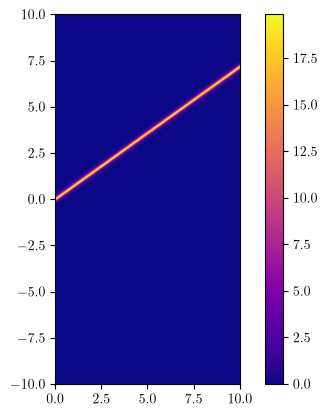

Порядок сходимости по z: 1.903


np.float64(1.9026402788644627)

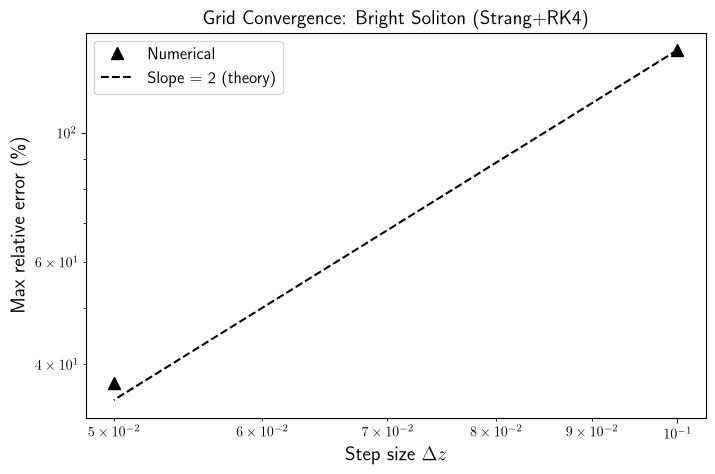

In [116]:
import numpy as np
import matplotlib.pyplot as plt


def convergence_study(params: dict, t_span: tuple, z_span: tuple):
    beta2 = params["beta2"]
    c0 = params["c0"]
    omega = params["omega"]

    # TODO from where??
    delta_required = (1.0 - beta2 * c0 * omega) / c0
    if abs(params["delta"] - delta_required) > 1e-6:
        print(f"⚠️ WARNING: delta={params['delta']} не согласовано!")
        print(f"   Для точного решения требуется delta = {delta_required:.6f}")
        print(f"   Подставляю корректное значение для теста.")
        params = params.copy()
        params["delta"] = delta_required


    model = PairedEquations(
        delta_beta=params["delta_beta"],
        beta2=params["beta2"],
        delta=params["delta"],
        gamma=params["gamma"],
        Omega_g=params["Omega_g"],
        g=params["g"],
    )

    fixed_dt = 0.005

    t_grid = Grid(fixed_dt, *t_span)
    dz_values = [
        0.1,
        0.05,
        # 0.01,
        # 0.005,
        # 0.0025,
        # 0.00125,
    ]

    errors = []
    for dz in dz_values:
        z_grid = Grid(dz, *z_span)
        u_num, v_num = None, None
        errors_dz = []
        for u, v, z in model.solve(
            t_grid,
            z_grid,
            initial_cond=model.bright_soliton_analytical(t_grid.points, 0, params),
        ):
            u_num, v_num = u, v
            # move grid!
            u_exact, _ = model.bright_soliton_analytical(t_grid.points, z, params)
            errors_dz.append(np.max(np.abs(u_num - u_exact)) / np.max(np.abs(u_exact)) * 100.0)

        errors.append(max(errors_dz))
        print(f"  dz={dz:<8.5f} | Max Rel Error = {errors[-1]:.4f}%")

    u, v = model.bright_soliton_analytical(t_grid.points, z_grid.points, params)
    plt.imshow(
        np.abs(u),
        extent=(*z_span, *t_span),
        cmap="plasma",
        origin='lower',
    )
    plt.colorbar()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(dz_values, errors, "^", color="black", markersize=8, label="Numerical")

    ref = [errors[0] * (dz / dz_values[0]) ** 2 for dz in dz_values]
    ax.loglog(
        dz_values, ref, "--", color="black", linewidth=1.5, label="Slope = 2 (theory)"
    )

    ax.set_xlabel("Step size $\\Delta z$", fontsize=14)
    ax.set_ylabel("Max relative error (\\%)", fontsize=14)
    # ax.ticklabel_format(style='sci', axis='x')
    # ax.ticklabel_format(style='sci', axis='y')

    ax.set_title("Grid Convergence: Bright Soliton (Strang+RK4)", fontsize=14)
    ax.legend(fontsize=12)
    # plt.grid(True, which="both", ls="-", alpha=0.3)

    # Реальный порядок
    slope = np.polyfit(np.log10(dz_values), np.log10(errors), 1)[0]
    print(f"Порядок сходимости по z: {slope:.3f}")
    return slope


# params_fig14 = {
#     "k": 12.8, "omega": 4.2, "w0": 0,
#     "beta2": 0.04, "Omega_g": 10, 
#     "gamma": -0.02,   # Fig. 14a
#     "g": 0, "delta_beta": 21,
#     "c0": 1.5,
# }
# delta_exact = (1.0 - params_fig14["beta2"] * params_fig14['c0'] * params_fig14["omega"]) / params_fig14['c0']
# params_fig14["delta"] = delta_exact

convergence_study(
    {
        "k": 13,
        "c0": 1.4,
        "omega": 5,
        "w0": 0,
        # eq
        "delta_beta": 25,
        "beta2": 0.025,
        "Omega_g": 10,
        "delta": 0.59,
        "gamma": -0.014,
        # "gamma": -0.153,
        "g": 0,
    },
    # params_fig14,
    t_span=(-10, 10),
    # z_span=(0, 50),
    z_span=(0, 10),
)